# Кластеризация ЕГЭ (8.5 если сделаны все задачи)

In [ ]:
!unzip -o cluster_ege.zip
%cd EGE
!pip install xlrd

unzip:  cannot find or open cluster_ege.zip, cluster_ege.zip.zip or cluster_ege.zip.ZIP.
[Errno 2] No such file or directory: 'EGE'
/content/EGE


Рядом лежат экселевские таблицы с координатами точек. В 3 и 4 задаче используется манхетеское расстояние. В остальных Евклидово.

* Постройте Распределение точек
* Кластеризуйте руками
* Постройте Распределение точек, отметьте принадлежность кластеров цветами
* Найдите среди в каждом кластере точку расстояние от которой до всех остальных минимально
* Выведите усреднение центров всех кластеров * 1000

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


## Решение. Часть 1: кластеризация «руками» (ЕГЭ, задание 27)

**Как решаем**

1. *Кластеризация руками* (без sklearn): точки считаем одним кластером, если их можно соединить цепочкой шагов длиной не больше `r` (связные компоненты). Чтобы не считать все пары, точки раскладываем по сетке со стороной `r`. Это даёт обход за примерно линейное время даже для 10 000 точек.
2. Радиус `r` выбираем **по графику плотности**: он должен быть больше типичного расстояния между соседями внутри кластера и меньше щели между кластерами. На практике смотрим, как число кластеров зависит от `r`, и берём середину «плато» (вывод `k(r)` под каждым графиком).
3. *Центр кластера* — точка самого кластера, у которой **сумма расстояний до остальных точек кластера минимальна** (медоид).
4. *Ответ*: `Px = среднее x центров · 1000`, `Py = среднее y центров · 1000`, берём целую часть (`int`, дробная часть отбрасывается).

**Метрики.** В задачах 3 и 4 — манхэттенское расстояние, в остальных — евклидово. Номера считаем с единицы, поэтому это `2.xlsx` и `3.xlsx` (пара «A/B» из прямоугольников, для которых манхэттенская метрика естественна). Для `3.xlsx` и `4.xlsx` ответ от метрики не зависит; для `2.xlsx` зависит. Сводная таблица с обоими вариантами — в конце части 1.

> Для чтения `.xls` нужен пакет `xlrd` (`pip install xlrd`).

In [ ]:
from collections import defaultdict
from itertools import cycle, islice

PALETTE = ["#377eb8", "#ff7f00", "#4daf4a", "#f781bf", "#a65628",
           "#984ea3", "#999999", "#e41a1c", "#dede00"]


def load_points(path):
    """Читает таблицу с координатами. В части файлов есть заголовок X, Y, в части его нет."""
    df = pd.read_excel(path, header=None)
    if isinstance(df.iloc[0, 0], str):
        df = df.iloc[1:]
    return df.astype(float).values


def dist(p, P, metric):
    """Расстояние от точки p до всех точек массива P."""
    d = np.abs(P - p)
    if metric == "euclid":
        return np.sqrt((d ** 2).sum(axis=1))
    return d.sum(axis=1)


def cluster_by_hand(X, r, metric):
    """Связные компоненты: i и j в одном кластере, если dist(i, j) <= r (транзитивно)."""
    n = len(X)
    cell = np.floor(X / r).astype(int)
    grid = defaultdict(list)
    for i, c in enumerate(map(tuple, cell)):
        grid[c].append(i)

    labels = -np.ones(n, dtype=int)
    k = 0
    for start in range(n):
        if labels[start] != -1:
            continue
        labels[start] = k
        stack = [start]
        while stack:
            i = stack.pop()
            cx, cy = cell[i]
            cand = []
            for dx in (-1, 0, 1):
                for dy in (-1, 0, 1):
                    cand += grid.get((cx + dx, cy + dy), [])
            cand = np.array(cand)
            cand = cand[labels[cand] == -1]
            if len(cand):
                near = cand[dist(X[i], X[cand], metric) <= r]
                labels[near] = k
                stack += near.tolist()
        k += 1
    return labels


def medoid(P, metric, chunk=500):
    """Индекс точки кластера с минимальной суммой расстояний до всех остальных."""
    best, best_i = np.inf, -1
    for s in range(0, len(P), chunk):
        sums = np.array([dist(p, P, metric).sum() for p in P[s:s + chunk]])
        j = sums.argmin()
        if sums[j] < best:
            best, best_i = sums[j], s + j
    return best_i


def solve(path, metric, r, title, plot=True, scan=True):
    X = load_points(path)
    labels = cluster_by_hand(X, r, metric)
    k = labels.max() + 1
    centers = np.array([X[labels == c][medoid(X[labels == c], metric)] for c in range(k)])
    px, py = centers.mean(axis=0) * 1000

    if plot:
        fig, ax = plt.subplots(1, 2, figsize=(13, 5))
        ax[0].scatter(X[:, 0], X[:, 1], s=4)
        ax[0].set_title(f"{title}: распределение точек (n={len(X)})")
        colors = np.array(list(islice(cycle(PALETTE), k)))
        ax[1].scatter(X[:, 0], X[:, 1], s=4, color=colors[labels])
        ax[1].scatter(centers[:, 0], centers[:, 1], marker="*", s=300, c="k",
                      edgecolors="w", zorder=3, label="центры (медоиды)")
        ax[1].set_title(f"{title}: {k} кластера(ов), метрика {metric}, r={r}")
        ax[1].legend()
        for a in ax:
            a.set_aspect("equal")
            a.grid(alpha=.3)
        plt.tight_layout()
        plt.show()

    if scan:
        ks = [(round(r * f, 3), cluster_by_hand(X, r * f, metric).max() + 1)
              for f in (0.25, 0.5, 1, 1.5, 2)]
        print("k(r) [число кластеров при разных r]:", ", ".join(f"r={a}: {b}" for a, b in ks))
    print("размеры кластеров:", np.bincount(labels).tolist())
    print("центры кластеров:")
    for c in centers:
        print(f"   ({c[0]:.4f}, {c[1]:.4f})")
    print(f"Px*1000 = {px:.3f},  Py*1000 = {py:.3f}")
    print(f"ОТВЕТ: {int(px)} {int(py)}")
    return dict(file=path, metric=metric, r=r, k=k, Px=int(px), Py=int(py))


In [ ]:
TASKS = [
    ("0.xls",   "euclid",    0.8),
    ("1.xls",   "euclid",    0.2),
    ("2.xlsx",  "manhattan", 2.5),
    ("3.xlsx",  "manhattan", 2.0),
    ("4.xlsx",  "euclid",    1.5),
    ("5.xlsx",  "euclid",    0.7),
]
R_ALT = {"0.xls": 1.0, "1.xls": 0.2, "2.xlsx": 2.0, "3.xlsx": 1.5, "4.xlsx": 2.0, "5.xlsx": 0.9}
answers = []

### Файл `0.xls` (Два кластера по 50 точек.)

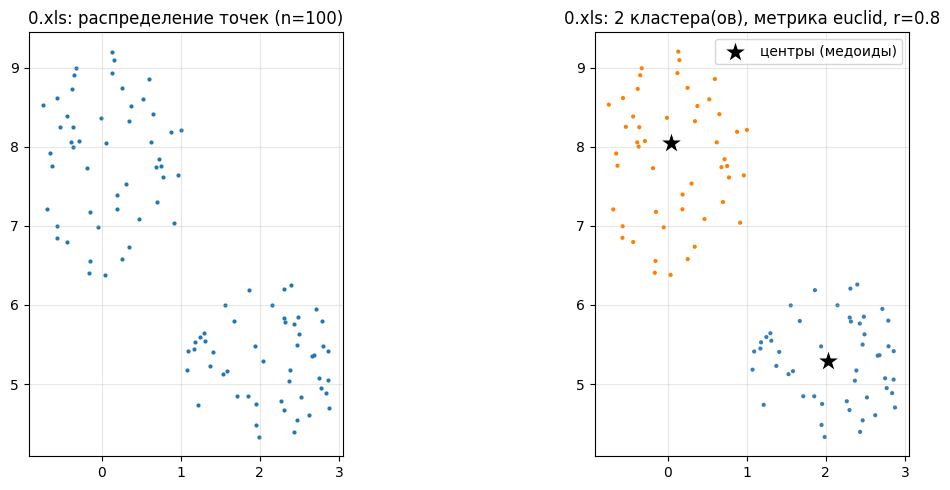

k(r) [число кластеров при разных r]: r=0.2: 46, r=0.4: 3, r=0.8: 2, r=1.2: 2, r=1.6: 1
размеры кластеров: [50, 50]
центры кластеров:
   (2.0339, 5.2893)
   (0.0481, 8.0531)
Px*1000 = 1041.006,  Py*1000 = 6671.173
ОТВЕТ: 1041 6671


In [ ]:
answers.append(solve("0.xls", "euclid", 0.8, "0.xls"))

### Файл `1.xls` (Три круга по 3333 точки.)

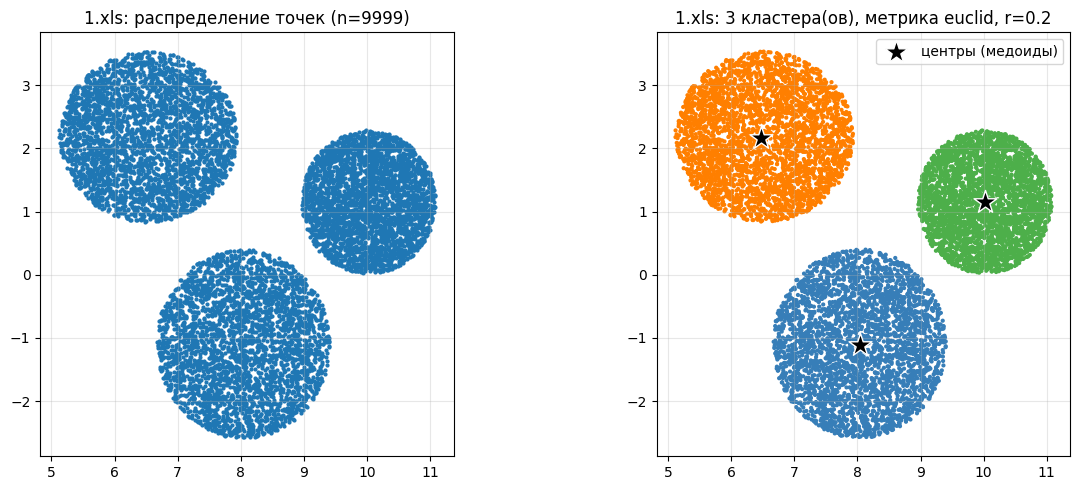

k(r) [число кластеров при разных r]: r=0.05: 353, r=0.1: 3, r=0.2: 3, r=0.3: 3, r=0.4: 3
размеры кластеров: [3333, 3333, 3333]
центры кластеров:
   (8.0401, -1.1087)
   (6.4700, 2.1698)
   (10.0225, 1.1542)
Px*1000 = 8177.531,  Py*1000 = 738.419
ОТВЕТ: 8177 738


In [ ]:
answers.append(solve("1.xls", "euclid", 0.2, "1.xls"))

### Файл `2.xlsx` (Два прямоугольника. Манхэттенская метрика.)

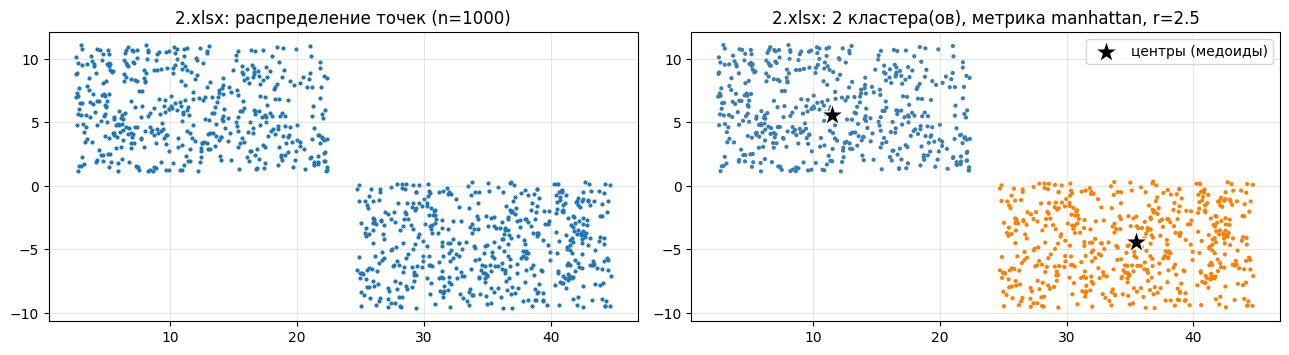

k(r) [число кластеров при разных r]: r=0.625: 326, r=1.25: 4, r=2.5: 2, r=3.75: 2, r=5.0: 1
размеры кластеров: [476, 524]
центры кластеров:
   (11.5036, 5.5592)
   (35.5162, -4.4498)
Px*1000 = 23509.903,  Py*1000 = 554.682
ОТВЕТ: 23509 554


In [ ]:
answers.append(solve("2.xlsx", "manhattan", 2.5, "2.xlsx"))

### Файл `3.xlsx` (Три прямоугольника. Манхэттенская метрика.)

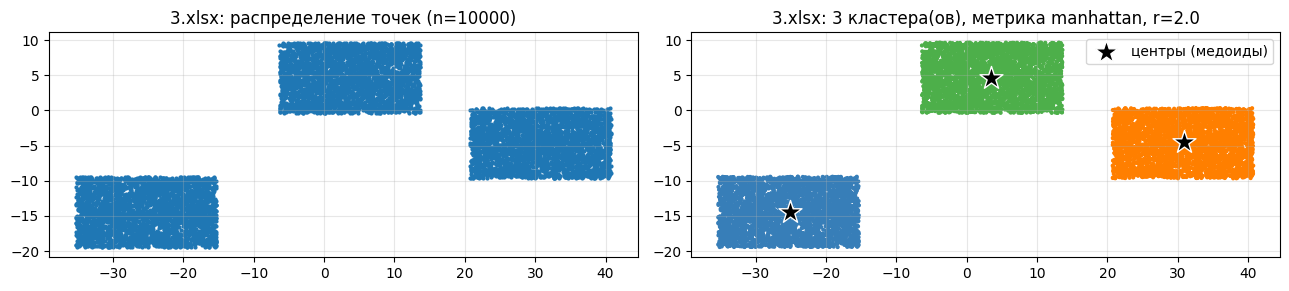

k(r) [число кластеров при разных r]: r=0.5: 13, r=1.0: 3, r=2.0: 3, r=3.0: 3, r=4.0: 3
размеры кластеров: [3429, 3287, 3284]
центры кластеров:
   (-25.1308, -14.4133)
   (30.8495, -4.5172)
   (3.5179, 4.6537)
Px*1000 = 3078.894,  Py*1000 = -4758.945
ОТВЕТ: 3078 -4758


In [ ]:
answers.append(solve("3.xlsx", "manhattan", 2.0, "3.xlsx"))

### Файл `4.xlsx` (Два облака по 250 точек (есть редкие одиночные точки у границы).)

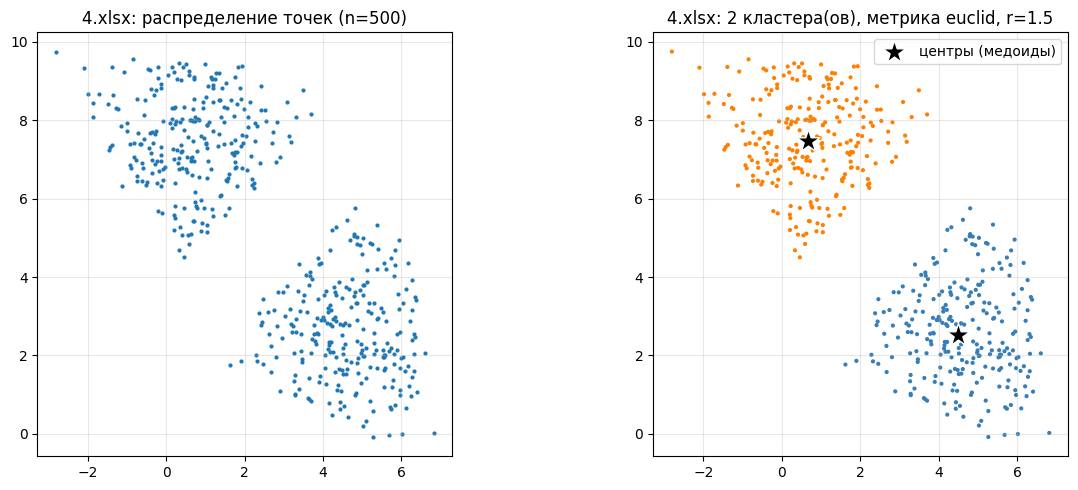

k(r) [число кластеров при разных r]: r=0.375: 28, r=0.75: 4, r=1.5: 2, r=2.25: 1, r=3.0: 1
размеры кластеров: [250, 250]
центры кластеров:
   (4.4993, 2.5248)
   (0.6778, 7.4683)
Px*1000 = 2588.540,  Py*1000 = 4996.568
ОТВЕТ: 2588 4996


In [ ]:
answers.append(solve("4.xlsx", "euclid", 1.5, "4.xlsx"))

### Файл `5.xlsx` (Три «треугольника» по 3333 точки.)

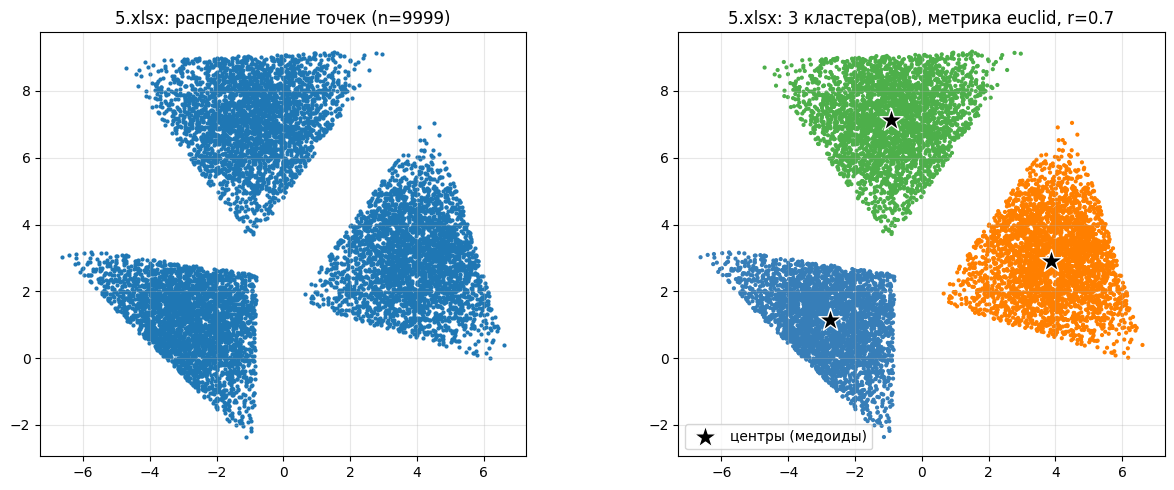

k(r) [число кластеров при разных r]: r=0.175: 47, r=0.35: 10, r=0.7: 3, r=1.05: 3, r=1.4: 2
размеры кластеров: [3333, 3333, 3333]
центры кластеров:
   (-2.7497, 1.1431)
   (3.8586, 2.9072)
   (-0.9240, 7.1199)
Px*1000 = 61.652,  Py*1000 = 3723.362
ОТВЕТ: 61 3723


In [ ]:
answers.append(solve("5.xlsx", "euclid", 0.7, "5.xlsx"))

# Кластеризация (0.75 за каждый алгоритм на всех данных)

На предложенных распределениях данных проверьте предложенные алгоритмы. Постройте графики кластеризации для каждой пары алгоритм-данные, разные кластеры покрасьте разным цветом. Воспользуйтесь sklearn реализациями. Параметры кластеризации для разных алгоритмов подберите такие, чтобы алгоритмы можно было сравнивать (по возможности одинаковое количество кластеров и т.д.)

In [ ]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from sklearn import cluster, datasets, mixture
from sklearn.neighbors import kneighbors_graph
from sklearn.preprocessing import StandardScaler
from itertools import cycle, islice
from sklearn.metrics import adjusted_rand_score


In [ ]:
two_means = cluster.MiniBatchKMeans(n_clusters=2, n_init="auto", random_state=0)
dbscan = cluster.DBSCAN(eps=0.3, min_samples=20)

clustering_algorithms = (
        ("MiniBatch\nKMeans", two_means),
        ("DBSCAN", dbscan),
    )

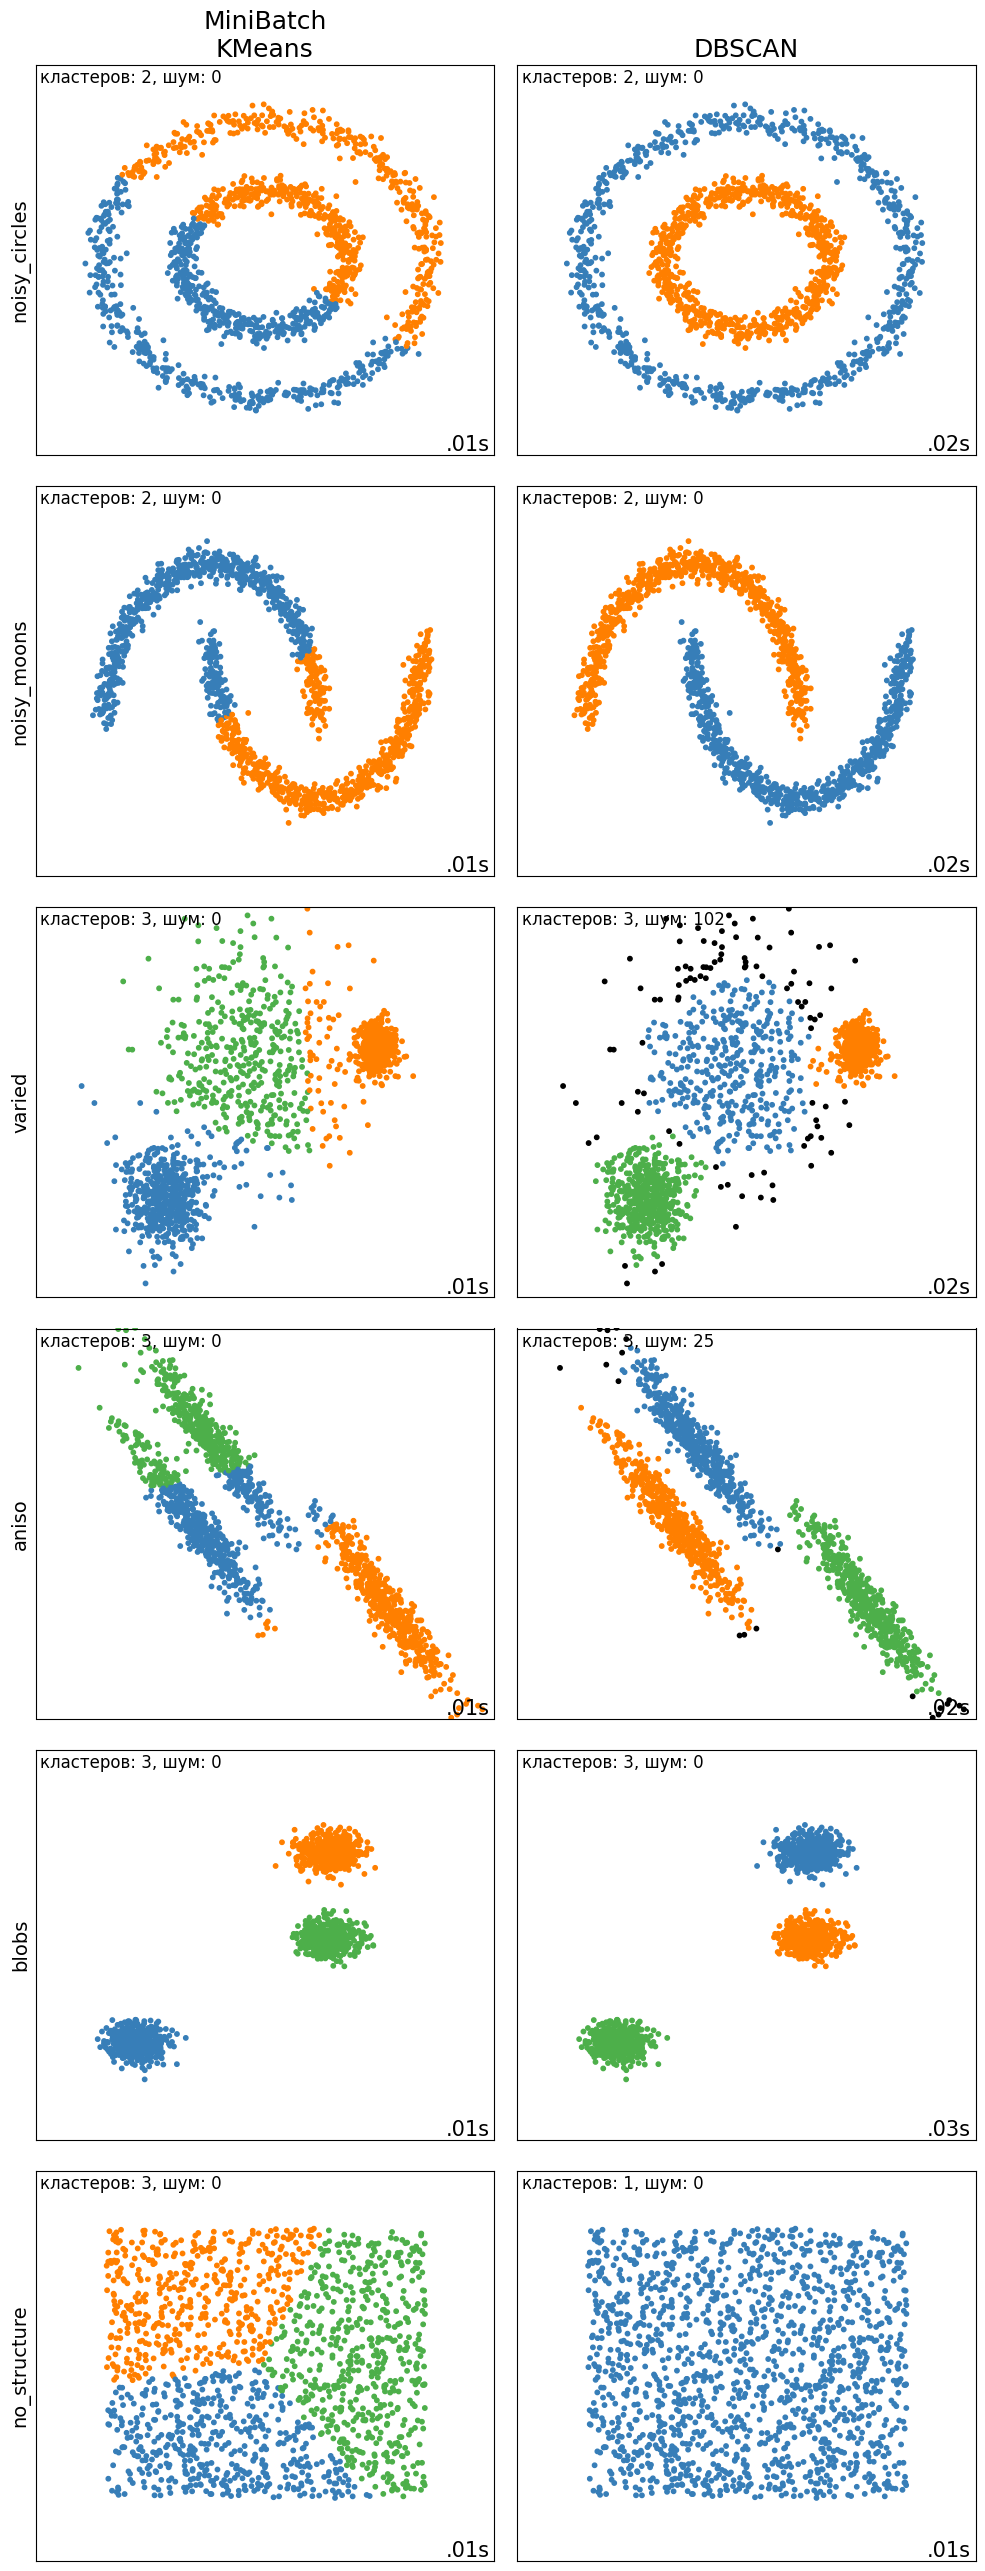

In [ ]:
np.random.seed(0)
n_samples = 1500
noisy_circles = datasets.make_circles(n_samples=n_samples, factor=0.5, noise=0.05)
noisy_moons = datasets.make_moons(n_samples=n_samples, noise=0.05)
blobs = datasets.make_blobs(n_samples=n_samples, random_state=8)
no_structure = np.random.rand(n_samples, 2), None
random_state = 170
X, y = datasets.make_blobs(n_samples=n_samples, random_state=random_state)
transformation = [[0.6, -0.6], [-0.4, 0.8]]
X_aniso = np.dot(X, transformation)
aniso = (X_aniso, y)
varied = datasets.make_blobs(
    n_samples=n_samples, cluster_std=[1.0, 2.5, 0.5], random_state=random_state
)

plt.figure(figsize=(10, 26))
plt.subplots_adjust(
    left=0.04, right=0.98, bottom=0.01, top=0.97, wspace=0.05, hspace=0.08
)

plot_num = 1
dataset_names = ["noisy_circles", "noisy_moons", "varied", "aniso", "blobs", "no_structure"]
results = []

default_base = {
    "quantile": 0.3,
    "eps": 0.3,
    "damping": 0.9,
    "preference": -200,
    "n_neighbors": 10,
    "n_clusters": 3,
    "min_samples": 20,
    "xi": 0.05,
    "min_cluster_size": 0.1,
}

datasets = [
    (
        noisy_circles,
        {
            "damping": 0.77,
            "preference": -240,
            "quantile": 0.2,
            "n_clusters": 2,
            "min_samples": 20,
            "xi": 0.25,
        },
    ),
    (noisy_moons, {"damping": 0.75, "preference": -220, "n_clusters": 2}),
    (
        varied,
        {
            "eps": 0.2,
            "n_neighbors": 2,
            "min_samples": 10,
            "xi": 0.035,
            "min_cluster_size": 0.2,
        },
    ),
    (
        aniso,
        {
            "eps": 0.2,
            "n_neighbors": 2,
            "min_samples": 10,
            "xi": 0.1,
            "min_cluster_size": 0.2,
        },
    ),
    (blobs, {}),
    (no_structure, {}),
]

for i_dataset, (dataset, algo_params) in enumerate(datasets):
    params = default_base.copy()
    params.update(algo_params)

    X, y = dataset
    X = StandardScaler().fit_transform(X)
    bandwidth = cluster.estimate_bandwidth(X, quantile=params["quantile"])
    connectivity = kneighbors_graph(
        X, n_neighbors=params["n_neighbors"], include_self=False
    )
    connectivity = 0.5 * (connectivity + connectivity.T)

    for name, algorithm in clustering_algorithms:
        t0 = time.time()
        if isinstance(algorithm, cluster.DBSCAN):
            algorithm.set_params(eps=params["eps"], min_samples=params["min_samples"])
        else:
            algorithm.set_params(n_clusters=params["n_clusters"])

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            algorithm.fit(X)

        t1 = time.time()
        y_pred = algorithm.labels_.astype(int)

        plt.subplot(len(datasets), len(clustering_algorithms), plot_num)
        if i_dataset == 0:
            plt.title(name, size=18)
        if plot_num % len(clustering_algorithms) == 1:
            plt.ylabel(dataset_names[i_dataset], size=14)

        colors = np.array(
            list(
                islice(
                    cycle(
                        ["#377eb8", "#ff7f00", "#4daf4a", "#f781bf", "#a65628",
                         "#984ea3", "#999999", "#e41a1c", "#dede00"]
                    ),
                    int(max(y_pred) + 1),
                )
            )
        )
        colors = np.append(colors, ["#000000"])
        plt.scatter(X[:, 0], X[:, 1], s=10, color=colors[y_pred])

        n_cl = len(set(y_pred)) - (1 if -1 in y_pred else 0)
        n_noise = int((y_pred == -1).sum())
        plt.xlim(-2.5, 2.5)
        plt.ylim(-2.5, 2.5)
        plt.xticks(())
        plt.yticks(())
        plt.text(0.01, 0.99, f"кластеров: {n_cl}, шум: {n_noise}", transform=plt.gca().transAxes,
                 size=12, verticalalignment="top")
        plt.text(0.99, 0.01, ("%.2fs" % (t1 - t0)).lstrip("0"), transform=plt.gca().transAxes,
                 size=15, horizontalalignment="right")
        plot_num += 1

        results.append(dict(
            dataset=dataset_names[i_dataset],
            algorithm=name.replace("\n", " "),
            clusters=n_cl,
            noise=n_noise,
            ARI=None if y is None else round(adjusted_rand_score(y, y_pred), 3),
        ))

plt.show()


### Выводы

Число кластеров задано одинаковым для обоих алгоритмов (2, 2, 3, 3, 3, 3). Для DBSCAN подобраны `eps` и `min_samples`, для MiniBatchKMeans - `n_clusters`.

* **MiniBatchKMeans** ищет компактные «шарообразные» кластеры вокруг центров. Идеален на `blobs` (ARI = 1). На `noisy_circles` (ARI ≈ 0) и `noisy_moons` (0.49) он режет фигуры прямой границей, потому что кластеры невыпуклые. На `aniso` (0.60) и `varied` (0.81) границы смещаются из-за вытянутой формы и разной дисперсии. Шума он не выделяет, а в `no_structure` честно делит равномерное облако на 3 части.
* **DBSCAN** опирается на плотность, а не на форму. Поэтому он безошибочно разделяет `noisy_circles`, `noisy_moons` и `blobs` (ARI = 1) и хорошо справляется с `aniso` (0.975). На `varied` (0.877) разреженный кластер частично уходит в шум (102 точки). В `no_structure` он видит одну сплошную область, и это корректно, ведь структуры там нет. Результат чувствителен к `eps` и `min_samples`, а число кластеров заранее не задаётся.
